In [1]:
from pathlib import Path
import json
import os
import random

import numpy as np
import pandas as pd

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

currentRoot = Path.cwd().resolve()
projectRoot = currentRoot.parent if currentRoot.name == 'notebooks' else currentRoot
if not (projectRoot / 'notebooks').exists():
    raise RuntimeError('Run this notebook from the project root or notebooks directory.')

dataRoot = projectRoot / 'data'
rawRoot = dataRoot / 'raw'
interimRoot = dataRoot / 'interim'
processedRoot = dataRoot / 'processed'
figureRoot = projectRoot / 'reports' / 'figures'
for outputRoot in (rawRoot, interimRoot, processedRoot, figureRoot):
    outputRoot.mkdir(parents=True, exist_ok=True)

configuredRawRoot = os.environ.get('SKIN_DATA_ROOT')
rawCandidates = [Path(configuredRawRoot).expanduser()] if configuredRawRoot else []
rawCandidates.extend([rawRoot, projectRoot.parent / 'Data'])

def containsDatasetFiles(path: Path) -> bool:
    datasetSuffixes = {'.csv', '.zip', '.jpg', '.jpeg', '.png', '.tif', '.tiff'}
    return path.exists() and any(
        candidate.is_file() and candidate.suffix.lower() in datasetSuffixes
        for candidate in path.rglob('*')
    )

sourceDataRoot = next((path.resolve() for path in rawCandidates if containsDatasetFiles(path)), None)
if sourceDataRoot is None:
    raise FileNotFoundError('No raw dataset found. Populate data/raw or set SKIN_DATA_ROOT.')

def toProjectPath(path: Path) -> str:
    return Path(os.path.relpath(path.resolve(), projectRoot)).as_posix()

def fromProjectPath(pathValue: str) -> Path:
    return (projectRoot / Path(pathValue)).resolve()

print(f'Project root: {projectRoot}')
print(f'Raw dataset root: {sourceDataRoot}')

Project root: D:\sunib\Research\Skin\skin-domain-shift
Raw dataset root: D:\sunib\Research\Skin\Data


In [2]:
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import hashlib
from itertools import combinations

import imagehash
from PIL import Image
from tqdm.auto import tqdm

PHASH_DISTANCE_THRESHOLD = 6
HASH_WORKERS = 8

clinicalSixClassPath = processedRoot / 'clinicalSixClass.csv'
isicValidatedPath = interimRoot / 'isicValidated.csv'
for requiredPath in (clinicalSixClassPath, isicValidatedPath):
    if not requiredPath.exists():
        raise FileNotFoundError(f'Run notebooks 02 and 03 first; missing {requiredPath.name}.')

clinicalManifest = pd.read_csv(clinicalSixClassPath, low_memory=False)
isicManifest = pd.read_csv(isicValidatedPath, low_memory=False)
isicManifest = isicManifest.loc[isicManifest['isValid'].astype(bool)].copy()
duplicateInput = pd.concat([clinicalManifest, isicManifest], ignore_index=True, sort=False)
if duplicateInput['imagePath'].duplicated().any():
    raise ValueError('Duplicate detection input contains repeated image paths.')
print(f'Images to hash: {len(duplicateInput):,}')

Images to hash: 35,867


In [3]:
def hashImage(record: dict) -> dict:
    imagePath = fromProjectPath(str(record['imagePath']))
    sha256 = hashlib.sha256()
    with imagePath.open('rb') as imageStream:
        for chunk in iter(lambda: imageStream.read(1024 * 1024), b''):
            sha256.update(chunk)
    with Image.open(imagePath) as image:
        perceptualHash = str(imagehash.phash(image.convert('RGB')))
    fileStat = imagePath.stat()
    return {
        'imagePath': record['imagePath'],
        'fileSize': int(fileStat.st_size),
        'modifiedNs': int(fileStat.st_mtime_ns),
        'sha256': sha256.hexdigest(),
        'pHash': perceptualHash,
    }

hashCachePath = interimRoot / 'imageHashCache.csv'
cacheColumns = ['imagePath', 'fileSize', 'modifiedNs', 'sha256', 'pHash']
hashCache = pd.read_csv(hashCachePath) if hashCachePath.exists() else pd.DataFrame(columns=cacheColumns)
cacheLookup = {
    (str(row.imagePath), int(row.fileSize), int(row.modifiedNs)): row._asdict()
    for row in hashCache.itertuples(index=False)
}

recordsToHash = []
cachedRecords = []
for record in duplicateInput[['imagePath', 'fileSize', 'modifiedNs']].to_dict('records'):
    cacheKey = (str(record['imagePath']), int(record['fileSize']), int(record['modifiedNs']))
    if cacheKey in cacheLookup and pd.notna(cacheLookup[cacheKey].get('sha256')) and pd.notna(cacheLookup[cacheKey].get('pHash')):
        cachedRecords.append({column: cacheLookup[cacheKey][column] for column in cacheColumns})
    else:
        recordsToHash.append(record)

with ThreadPoolExecutor(max_workers=HASH_WORKERS) as executor:
    calculatedRecords = list(tqdm(executor.map(hashImage, recordsToHash), total=len(recordsToHash), desc='Hashing images'))
currentHashes = pd.DataFrame([*cachedRecords, *calculatedRecords], columns=cacheColumns)
currentHashes = currentHashes.drop_duplicates('imagePath', keep='last')
currentHashes.to_csv(hashCachePath, index=False)
duplicateInput = duplicateInput.drop(columns=['sha256'], errors='ignore').merge(
    currentHashes, on=['imagePath', 'fileSize', 'modifiedNs'], how='left', validate='one_to_one'
)
assert duplicateInput[['sha256', 'pHash']].notna().all().all()
print(f'Reused cached hashes: {len(cachedRecords):,}; calculated: {len(calculatedRecords):,}')

Hashing images: 0it [00:00, ?it/s]

Reused cached hashes: 35,867; calculated: 0


In [4]:
exactRows = []
duplicateGroupRows = []
exactGroupNumber = 0
for shaValue, group in duplicateInput.groupby('sha256', sort=True):
    if len(group) < 2:
        continue
    exactGroupNumber += 1
    duplicateGroup = f'exact-{exactGroupNumber:05d}'
    sourceScope = 'crossDataset' if group['sourceDataset'].nunique() > 1 else 'withinDataset'
    for row in group.itertuples(index=False):
        exactRows.append({
            'duplicateGroup': duplicateGroup,
            'sha256': shaValue,
            'sourceScope': sourceScope,
            'imageId': row.imageId,
            'imagePath': row.imagePath,
            'sourceDataset': row.sourceDataset,
        })
        duplicateGroupRows.append({
            'duplicateGroup': duplicateGroup,
            'imageId': row.imageId,
            'imagePath': row.imagePath,
            'sourceDataset': row.sourceDataset,
            'confirmationBasis': 'sha256',
        })

exactDuplicates = pd.DataFrame(exactRows, columns=[
    'duplicateGroup', 'sha256', 'sourceScope', 'imageId', 'imagePath', 'sourceDataset'
])
duplicateGroups = pd.DataFrame(duplicateGroupRows, columns=[
    'duplicateGroup', 'imageId', 'imagePath', 'sourceDataset', 'confirmationBasis'
])
exactDuplicatesPath = processedRoot / 'exactDuplicates.csv'
duplicateGroupsPath = processedRoot / 'duplicateGroups.csv'
exactDuplicates.to_csv(exactDuplicatesPath, index=False)
duplicateGroups.to_csv(duplicateGroupsPath, index=False)
print(f'Exact duplicate groups: {exactGroupNumber}; affected images: {len(exactDuplicates)}')

Exact duplicate groups: 65; affected images: 130


In [5]:
hashRecords = duplicateInput[['imageId', 'imagePath', 'sourceDataset', 'sha256', 'pHash']].reset_index(drop=True)

def hammingDistance(leftValue: int, rightValue: int) -> int:
    return (leftValue ^ rightValue).bit_count()

class HammingBkTree:
    def __init__(self):
        self.root = None

    def add(self, hashValue: int, rowIndex: int) -> None:
        if self.root is None:
            self.root = [hashValue, [(rowIndex, hashValue)], {}]
            return
        node = self.root
        while True:
            distance = hammingDistance(hashValue, node[0])
            if distance == 0:
                node[1].append((rowIndex, hashValue))
                return
            if distance not in node[2]:
                node[2][distance] = [hashValue, [(rowIndex, hashValue)], {}]
                return
            node = node[2][distance]

    def search(self, hashValue: int, maxDistance: int) -> list[tuple[int, int]]:
        if self.root is None:
            return []
        matches = []
        pendingNodes = [self.root]
        while pendingNodes:
            node = pendingNodes.pop()
            distance = hammingDistance(hashValue, node[0])
            if distance <= maxDistance:
                matches.extend((rowIndex, distance) for rowIndex, _ in node[1])
            lowerDistance = distance - maxDistance
            upperDistance = distance + maxDistance
            pendingNodes.extend(
                childNode for edgeDistance, childNode in node[2].items()
                if lowerDistance <= edgeDistance <= upperDistance
            )
        return matches

nearRows = []
candidatePairCount = 0
hashTree = HammingBkTree()
for rightIndex, rightRow in tqdm(hashRecords.iterrows(), total=len(hashRecords), desc='Searching pHash neighbors'):
    rightHashValue = int(rightRow['pHash'], 16)
    for leftIndex, distance in hashTree.search(rightHashValue, PHASH_DISTANCE_THRESHOLD):
        candidatePairCount += 1
        leftRow = hashRecords.iloc[leftIndex]
        if leftRow['sha256'] == rightRow['sha256']:
            continue
        nearRows.append({
            'leftImageId': leftRow['imageId'],
            'leftImagePath': leftRow['imagePath'],
            'leftSourceDataset': leftRow['sourceDataset'],
            'rightImageId': rightRow['imageId'],
            'rightImagePath': rightRow['imagePath'],
            'rightSourceDataset': rightRow['sourceDataset'],
            'pHashDistance': int(distance),
            'reviewStatus': 'manualReviewRequired',
        })
    hashTree.add(rightHashValue, rightIndex)

nearDuplicateCandidates = pd.DataFrame(nearRows, columns=[
    'leftImageId', 'leftImagePath', 'leftSourceDataset', 'rightImageId', 'rightImagePath',
    'rightSourceDataset', 'pHashDistance', 'reviewStatus'
]).sort_values(['pHashDistance', 'leftImageId', 'rightImageId'], ignore_index=True)
nearDuplicateCandidatesPath = processedRoot / 'nearDuplicateCandidates.csv'
nearDuplicateCandidates.to_csv(nearDuplicateCandidatesPath, index=False)
print(f'Generated pairs: {candidatePairCount:,}; flagged near-duplicate candidates: {len(nearDuplicateCandidates):,}')
nearDuplicateCandidates.head(10)

Searching pHash neighbors:   0%|          | 0/35867 [00:00<?, ?it/s]

Generated pairs: 13,613; flagged near-duplicate candidates: 13,548


,leftImageId,leftImagePath,leftSourceDataset,rightImageId,rightImagePath,rightSourceDataset,pHashDistance,reviewStatus
0,ISIC_0000519_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0011295,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
1,ISIC_0012222_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0016003_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
2,ISIC_0012290_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0013594_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
3,ISIC_0012887_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0012989_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
4,ISIC_0015986_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0015987_downsampled,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
5,ISIC_0024333,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0024630,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
6,ISIC_0024394,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0029516,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
7,ISIC_0024658,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0026272,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
8,ISIC_0024753,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0027519,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired
9,ISIC_0024870,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,ISIC_0025386,../Data/Train/ISIC_2019_Training_Input/ISIC_00...,isic2019,0,manualReviewRequired


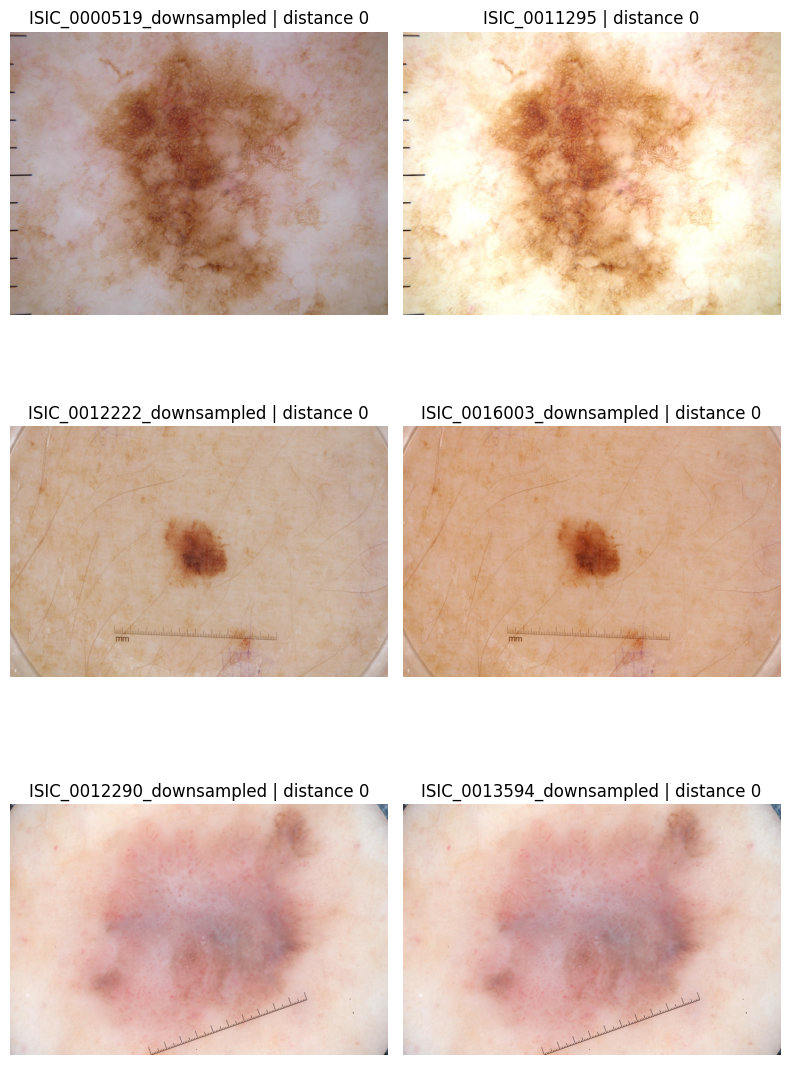

{
  "imageCount": 35867,
  "hashCachePath": "data/interim/imageHashCache.csv",
  "exactDuplicateGroupCount": 65,
  "exactDuplicateImageCount": 130,
  "crossDatasetExactGroupCount": 0,
  "candidatePairCount": 13613,
  "nearDuplicateCandidateCount": 13548,
  "pHashDistanceThreshold": 6,
  "nearDuplicatesAutomaticallyRemoved": false
}


In [6]:
import matplotlib.pyplot as plt

nearFigurePath = figureRoot / 'nearDuplicateExamples.png'
if len(nearDuplicateCandidates):
    exampleFrame = nearDuplicateCandidates.head(3)
    figure, axes = plt.subplots(len(exampleFrame), 2, figsize=(8, 4 * len(exampleFrame)), squeeze=False)
    for rowIndex, row in enumerate(exampleFrame.itertuples(index=False)):
        for columnIndex, (imagePathValue, imageId) in enumerate([
            (row.leftImagePath, row.leftImageId), (row.rightImagePath, row.rightImageId)
        ]):
            with Image.open(fromProjectPath(imagePathValue)) as image:
                axes[rowIndex, columnIndex].imshow(image.convert('RGB'))
            axes[rowIndex, columnIndex].set_title(f'{imageId} | distance {row.pHashDistance}')
            axes[rowIndex, columnIndex].axis('off')
    figure.tight_layout()
    figure.savefig(nearFigurePath, dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('No near-duplicate candidates were available for a review figure.')

duplicateReport = {
    'imageCount': len(duplicateInput),
    'hashCachePath': toProjectPath(hashCachePath),
    'exactDuplicateGroupCount': exactGroupNumber,
    'exactDuplicateImageCount': len(exactDuplicates),
    'crossDatasetExactGroupCount': int(exactDuplicates.loc[exactDuplicates['sourceScope'].eq('crossDataset'), 'duplicateGroup'].nunique()) if len(exactDuplicates) else 0,
    'candidatePairCount': candidatePairCount,
    'nearDuplicateCandidateCount': len(nearDuplicateCandidates),
    'pHashDistanceThreshold': PHASH_DISTANCE_THRESHOLD,
    'nearDuplicatesAutomaticallyRemoved': False,
}
duplicateReportPath = processedRoot / 'duplicateReport.json'
duplicateReportPath.write_text(json.dumps(duplicateReport, indent=2), encoding='utf-8')
print(json.dumps(duplicateReport, indent=2))

In [7]:
import tempfile

with tempfile.TemporaryDirectory(dir=interimRoot) as temporaryName:
    temporaryRoot = Path(temporaryName)
    firstPath = temporaryRoot / 'first.png'
    secondPath = temporaryRoot / 'second.png'
    Image.new('RGB', (16, 16), color=(100, 50, 25)).save(firstPath)
    secondPath.write_bytes(firstPath.read_bytes())
    firstHash = hashlib.sha256(firstPath.read_bytes()).hexdigest()
    secondHash = hashlib.sha256(secondPath.read_bytes()).hexdigest()
    assert firstHash == secondHash
    assert imagehash.phash(Image.open(firstPath)) - imagehash.phash(Image.open(secondPath)) == 0
syntheticHashes = [int(value) for value in np.random.default_rng(RANDOM_SEED).integers(0, 2 ** 63, size=200)]
syntheticTree = HammingBkTree()
for rowIndex, hashValue in enumerate(syntheticHashes):
    treeMatches = {index for index, _ in syntheticTree.search(hashValue, PHASH_DISTANCE_THRESHOLD)}
    exhaustiveMatches = {
        index for index, priorValue in enumerate(syntheticHashes[:rowIndex])
        if hammingDistance(hashValue, priorValue) <= PHASH_DISTANCE_THRESHOLD
    }
    assert treeMatches == exhaustiveMatches
    syntheticTree.add(hashValue, rowIndex)
print('Synthetic duplicate checks passed.')

Synthetic duplicate checks passed.
